# Unidad IV - Análisis no supervisado
## K-Means y PCA

**Alumno:** Mark Alan Moya Galindo  
**Proyecto:** Predicción de demanda en un sistema de bicicletas compartidas  
**Dataset:** Bike Sharing

### Objetivo
Identificar patrones y agrupamientos en los registros mediante **K-Means** y representar los datos con **PCA** para interpretar perfiles de uso relacionados con horario, clima y demanda.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

def localizar_raiz():
    actual = Path.cwd()
    for ruta in [actual, actual.parent]:
        if (ruta / "data").exists():
            return ruta
    raise FileNotFoundError("No se encontro la raiz del proyecto")

ROOT = localizar_raiz()
PROCESSED = ROOT / "data" / "processed" / "bike_sharing_clean.csv"
RAW = ROOT / "data" / "raw" / "hour.csv"

DATA_PATH = PROCESSED if PROCESSED.exists() else RAW
df = pd.read_csv(DATA_PATH)

print("Dataset utilizado:", DATA_PATH)
print("Registros:", len(df))
print("Columnas:", len(df.columns))


Dataset utilizado: C:\bike-sharing-demand-U2-AE1\data\processed\bike_sharing_clean.csv
Registros: 17379
Columnas: 25


**Interpretación:** se utiliza preferentemente el dataset procesado generado por el ETL. El archivo original permanece separado en `data/raw/`.


## 1. Selección de variables

In [2]:
FEATURES = [
    "hr",
    "weekday",
    "season",
    "weathersit",
    "temp",
    "hum",
    "windspeed",
    "cnt",
]

X = df[FEATURES].copy()
X.head()


,hr,weekday,season,weathersit,temp,hum,windspeed,cnt
0,0,6,1,1,0.24,0.81,0.0,16
1,1,6,1,1,0.22,0.80,0.0,40
2,2,6,1,1,0.22,0.80,0.0,32
3,3,6,1,1,0.24,0.75,0.0,13
4,4,6,1,1,0.24,0.75,0.0,1


### Justificación
- `hr`: patrones por hora.
- `weekday`: diferencias por día.
- `season`: efecto de temporada.
- `weathersit`: condición climática.
- `temp`, `hum`, `windspeed`: contexto meteorológico.
- `cnt`: nivel real de demanda.

No se utiliza `instant` porque es un identificador y no describe el comportamiento del sistema.


## 2. Estandarización

In [3]:
print("Valores faltantes:")
print(X.isna().sum())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Matriz estandarizada:", X_scaled.shape)


Valores faltantes:
hr            0
weekday       0
season        0
weathersit    0
temp          0
hum           0
windspeed     0
cnt           0
dtype: int64
Matriz estandarizada: (17379, 8)


**Interpretación:** K-Means trabaja con distancias. La estandarización evita que una variable con escala grande, como `cnt`, domine el cálculo frente a variables normalizadas.


## 3. Evaluación del número de clusters

In [4]:
resultados = []

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )
    etiquetas = modelo.fit_predict(X_scaled)

    sil = silhouette_score(
        X_scaled,
        etiquetas,
        sample_size=min(5000, len(X_scaled)),
        random_state=42,
    )

    resultados.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silhouette": sil,
    })

metricas_k = pd.DataFrame(resultados)
metricas_k


,k,inercia,silhouette
0,2,114264.447771,0.166909
1,3,99342.340177,0.172447
2,4,89474.494260,0.177637
3,5,83671.605864,0.162322
4,6,79307.513849,0.153141
5,7,75595.316350,0.150761
6,8,72306.904650,0.142746


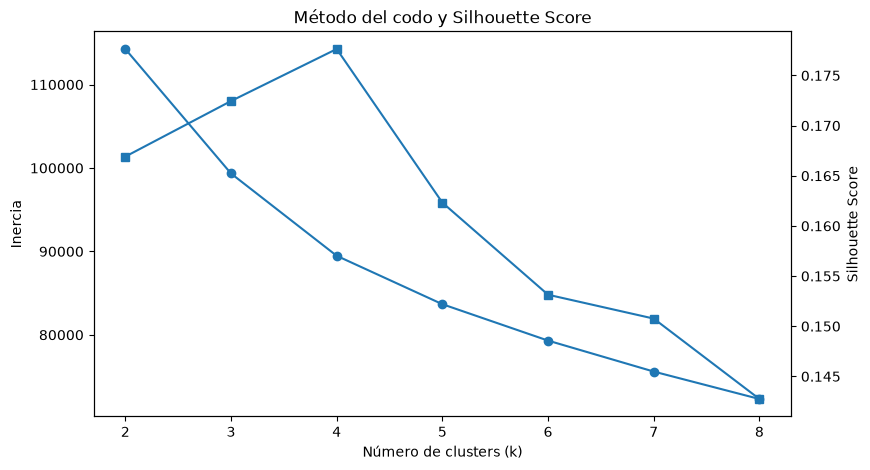

In [5]:
fig, ax1 = plt.subplots(figsize=(9,5))
ax1.plot(metricas_k["k"], metricas_k["inercia"], marker="o")
ax1.set_xlabel("Número de clusters (k)")
ax1.set_ylabel("Inercia")

ax2 = ax1.twinx()
ax2.plot(metricas_k["k"], metricas_k["silhouette"], marker="s")
ax2.set_ylabel("Silhouette Score")

plt.title("Método del codo y Silhouette Score")
plt.show()


**Interpretación:** la inercia ayuda a observar el punto donde agregar más clusters aporta cada vez menos mejora. El Silhouette Score permite comparar la separación entre grupos; valores más altos indican mejor separación relativa.


## 4. Entrenamiento de K-Means

In [6]:
mejor_k = int(
    metricas_k.loc[
        metricas_k["silhouette"].idxmax(),
        "k",
    ]
)

kmeans = KMeans(
    n_clusters=mejor_k,
    random_state=42,
    n_init=20,
)

clusters = kmeans.fit_predict(X_scaled)

df_clusters = X.copy()
df_clusters["cluster"] = clusters

print("Mejor k:", mejor_k)
print(
    "Silhouette:",
    metricas_k.loc[
        metricas_k["k"] == mejor_k,
        "silhouette",
    ].iloc[0],
)


Mejor k: 4
Silhouette: 0.17763662449913162


## 5. Perfil de los clusters

In [7]:
resumen_clusters = (
    df_clusters.groupby("cluster")
    .agg(
        registros=("cluster","size"),
        hora_promedio=("hr","mean"),
        demanda_promedio=("cnt","mean"),
        temperatura_promedio=("temp","mean"),
        humedad_promedio=("hum","mean"),
        viento_promedio=("windspeed","mean"),
        clima_promedio=("weathersit","mean"),
        temporada_promedio=("season","mean"),
    )
    .round(3)
)

resumen_clusters


,registros,hora_promedio,demanda_promedio,temperatura_promedio,humedad_promedio,viento_promedio,clima_promedio,temporada_promedio
cluster,,,,,,,,
0,6228,15.826,346.556,0.633,0.526,0.199,1.149,2.962
1,4110,4.033,57.381,0.499,0.748,0.123,1.231,3.013
2,3295,12.421,146.343,0.462,0.817,0.197,2.415,2.515
3,3746,11.906,111.130,0.301,0.497,0.242,1.227,1.164


**Interpretación:** esta tabla es la base para describir cada cluster. Un grupo con demanda promedio alta puede representar horas de uso intenso; otro con baja demanda y horas tempranas puede corresponder a periodos de baja actividad.


## 6. PCA

In [8]:
pca = PCA(n_components=2)
componentes = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    componentes,
    columns=["PC1","PC2"],
)
pca_df["cluster"] = clusters

print("Varianza PC1:", pca.explained_variance_ratio_[0])
print("Varianza PC2:", pca.explained_variance_ratio_[1])
print("Varianza total:", pca.explained_variance_ratio_.sum())


Varianza PC1: 0.2528262242859417
Varianza PC2: 0.18618709326634972
Varianza total: 0.43901331755229145


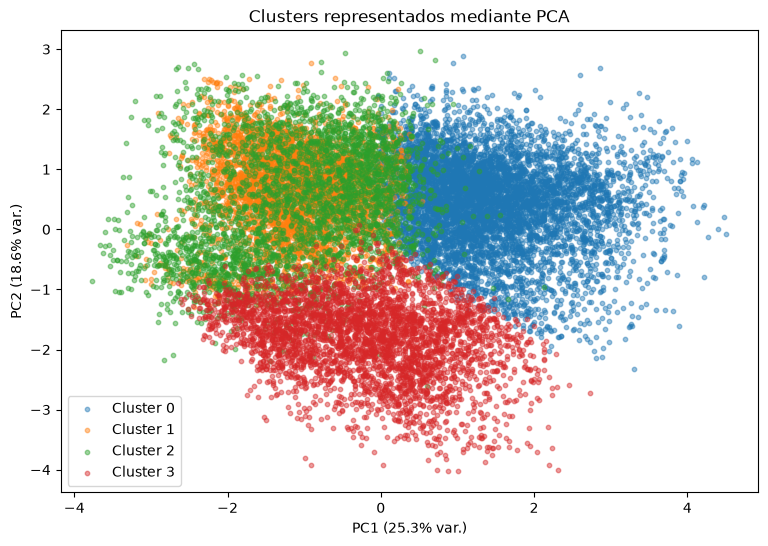

In [9]:
plt.figure(figsize=(9,6))

for cluster in sorted(pca_df["cluster"].unique()):
    sub = pca_df[pca_df["cluster"] == cluster]
    plt.scatter(
        sub["PC1"],
        sub["PC2"],
        s=10,
        alpha=.45,
        label=f"Cluster {cluster}",
    )

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var.)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var.)")
plt.title("Clusters representados mediante PCA")
plt.legend()
plt.show()


**Interpretación:** PCA resume la información de varias variables en dos componentes. La gráfica ayuda a visualizar si los clusters tienen separación clara o si algunos grupos se superponen.


## 7. Conclusión

Después de ejecutar el notebook debes poder explicar:

1. Qué variables utilizaste y por qué.
2. Por qué fue necesario estandarizar.
3. Cómo comparaste distintos valores de `k`.
4. Qué valor de `k` resultó seleccionado.
5. Qué significa el Silhouette Score.
6. Qué características tiene cada cluster.
7. Cuánta varianza explican PC1 y PC2.
8. Si los grupos tienen sentido respecto a horario, clima y demanda.
